# ML Project 1

## Setup and Imports

In [70]:
import importlib
import matplotlib.pyplot as plt
import numpy as np

import evals
import implementations
import preprocessing

importlib.reload(evals)
importlib.reload(implementations)
importlib.reload(preprocessing)

from evals import accuracy_from_model, accuracy_from_predictions, f1_score
from helpers import load_csv_data, create_csv_submission
from implementations import negative_log_likelihood, reg_logistic_regression, sigmoid, sgd_for_svm_demo
from preprocessing import add_bias, balance_dataset, train_val_split

In [71]:
SEED = 43
np.random.seed(SEED)

In [138]:
BEST_MODEL_FILE_PATH = "best_model_weights.npy"

## Loading the data

In [72]:
path = "data/dataset"

x_train_data, x_test_data, y_train_data, train_ids, test_ids = load_csv_data(path)

## Preprocessing the data

The raw BRFSS data contains survey-specific codes, administrative columns, missing
values, and variables measured on different scales. We preprocess the data in the
following order:

1. **Clean survey codes:** Convert “don't know”, “refused”, and invalid values to
   `NaN`. We also translate skip-logic blanks into meaningful values where the
   answer can be inferred safely.
2. **Transform encoded variables:** Convert frequency and duration codes into
   numerical values, such as occurrences per 30 days or exercise duration in
   minutes.
3. **Filter features:** Remove identifiers, administrative variables, survey
   weights, constant columns, and columns with more than 50% missing values.
4. **Split the training data:** Create a validation set while keeping the test set
   completely separate.
5. **Impute missing values:** Use training-set statistics only. Categorical
   variables are filled with their mode, while continuous variables are filled
   with their median. Missingness indicators are added for informative missing
   values.
6. **Standardize numerical features:** Apply z-score standardization using
   parameters learned from the training set and reuse those parameters for the
   validation and test sets.
7. **Add the bias term and balance the classes:** Add a bias column for the models
   and downsample the majority class in the training data.

In [73]:
HEADER = """_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNCR,CHCOCNCR,CHCCOPD1,HAVARTH3,ADDEPEV2,CHCKIDNY,DIABETE3,DIABAGE2,SEX,MARITAL,EDUCA,RENTHOM1,NUMHHOL2,NUMPHON2,CPDEMO1,VETERAN3,EMPLOY1,CHILDREN,INCOME2,INTERNET,WEIGHT2,HEIGHT3,PREGNANT,QLACTLM2,USEEQUIP,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,SMOKE100,SMOKDAY2,STOPSMK2,LASTSMK2,USENOW3,ALCDAY5,AVEDRNK2,DRNK3GE5,MAXDRNKS,FRUITJU1,FRUIT1,FVBEANS,FVGREEN,FVORANG,VEGETAB1,EXERANY2,EXRACT11,EXEROFT1,EXERHMM1,EXRACT21,EXEROFT2,EXERHMM2,STRENGTH,LMTJOIN3,ARTHDIS2,ARTHSOCL,JOINPAIN,SEATBELT,FLUSHOT6,FLSHTMY2,IMFVPLAC,PNEUVAC3,HIVTST6,HIVTSTD3,WHRTST10,PDIABTST,PREDIAB1,INSULIN,BLDSUGAR,FEETCHK2,DOCTDIAB,CHKHEMO3,FEETCHK,EYEEXAM,DIABEYE,DIABEDU,CAREGIV1,CRGVREL1,CRGVLNG1,CRGVHRS1,CRGVPRB1,CRGVPERS,CRGVHOUS,CRGVMST2,CRGVEXPT,VIDFCLT2,VIREDIF3,VIPRFVS2,VINOCRE2,VIEYEXM2,VIINSUR2,VICTRCT4,VIGLUMA2,VIMACDG2,CIMEMLOS,CDHOUSE,CDASSIST,CDHELP,CDSOCIAL,CDDISCUS,WTCHSALT,LONGWTCH,DRADVISE,ASTHMAGE,ASATTACK,ASERVIST,ASDRVIST,ASRCHKUP,ASACTLIM,ASYMPTOM,ASNOSLEP,ASTHMED3,ASINHALR,HAREHAB1,STREHAB1,CVDASPRN,ASPUNSAF,RLIVPAIN,RDUCHART,RDUCSTRK,ARTTODAY,ARTHWGT,ARTHEXER,ARTHEDU,TETANUS,HPVADVC2,HPVADSHT,SHINGLE2,HADMAM,HOWLONG,HADPAP2,LASTPAP2,HPVTEST,HPLSTTST,HADHYST2,PROFEXAM,LENGEXAM,BLDSTOOL,LSTBLDS3,HADSIGM3,HADSGCO1,LASTSIG3,PCPSAAD2,PCPSADI1,PCPSARE1,PSATEST1,PSATIME,PCPSARS1,PCPSADE1,PCDMDECN,SCNTMNY1,SCNTMEL1,SCNTPAID,SCNTWRK1,SCNTLPAD,SCNTLWK1,SXORIENT,TRNSGNDR,RCSGENDR,RCSRLTN2,CASTHDX2,CASTHNO2,EMTSUPRT,LSATISFY,ADPLEASR,ADDOWN,ADSLEEP,ADENERGY,ADEAT1,ADFAIL,ADTHINK,ADMOVE,MISTMNT,ADANXEV,QSTVER,QSTLANG,MSCODE,_STSTR,_STRWT,_RAWRAKE,_WT2RAKE,_CHISPNC,_CRACE1,_CPRACE,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPWT,_RFHLTH,_HCVU651,_RFHYPE5,_CHOLCHK,_RFCHOL,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR1,_PRACE1,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACE_G1,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,BMI5CAT,RFBMI5,CHLDCNT,EDUCAG,INCOMG,SMOKER3,RFSMOK3,DRNKANY5,DROCDY3,RFBING5,DRNKWEK,RFDRHV5,FTJUDA1,FRUTDA1,BEANDAY,GRENDAY,ORNGDAY,VEGEDA1,MISFRTN,MISVEGN,FRTRESP,VEGRESP,FRUTSUM,VEGESUM,FRTLT1,VEGLT1,FRT16,VEG23,FRUITEX,VEGETEX,TOTINDA,METVL11,METVL21,MAXVO2,FC60,ACTIN11,ACTIN21,PADUR1,PADUR2,PAFREQ1,PAFREQ2,MINAC11,MINAC21,STRFREQ,PAMISS1,PAMIN11,PAMIN21,PA1MIN,PAVIG11,PAVIG21,PA1VIGM,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3""".split(
    ","
)
IDX = {n: i for i, n in enumerate(HEADER)}

# ---- codes that mean "don't know / refused" -> NaN (from the codebook) ----
DK = {}
for n in [
    "HLTHPLN1",
    "MEDCOST",
    "BPMEDS",
    "BLOODCHO",
    "TOLDHI2",
    "CVDSTRK3",
    "ASTHMA3",
    "ASTHNOW",
    "CHCSCNCR",
    "CHCOCNCR",
    "CHCCOPD1",
    "HAVARTH3",
    "ADDEPEV2",
    "CHCKIDNY",
    "VETERAN3",
    "INTERNET",
    "QLACTLM2",
    "USEEQUIP",
    "BLIND",
    "DECIDE",
    "DIFFWALK",
    "DIFFDRES",
    "DIFFALON",
    "SMOKE100",
    "SMOKDAY2",
    "STOPSMK2",
    "USENOW3",
    "EXERANY2",
    "FLUSHOT6",
    "PNEUVAC3",
    "HIVTST6",
    "PREGNANT",
    "LMTJOIN3",
    "ARTHDIS2",
    "GENHLTH",
    "PERSDOC2",
    "CHECKUP1",
    "CHOLCHK",
    "BPHIGH4",
    "DIABETE3",
    "RENTHOM1",
    "SEATBELT",
]:
    DK[n] = [7, 9]
DK.update(
    {
        "EDUCA": [9],
        "MARITAL": [9],
        "EMPLOY1": [9],
        "INCOME2": [77, 99],
        "LASTSMK2": [77, 99],
        "PHYSHLTH": [77, 99],
        "MENTHLTH": [77, 99],
        "POORHLTH": [77, 99],
        "DRNK3GE5": [77, 99],
        "AVEDRNK2": [77, 99],
        "MAXDRNKS": [77, 99],
        "JOINPAIN": [77, 99],
        "CHILDREN": [99],
        "DIABAGE2": [98, 99],
        "WEIGHT2": [7777, 9999],
        "HEIGHT3": [7777, 9999],
    }
)
for n in [
    "ALCDAY5",
    "FRUITJU1",
    "FRUIT1",
    "FVBEANS",
    "FVGREEN",
    "FVORANG",
    "VEGETAB1",
    "EXEROFT1",
    "EXEROFT2",
    "STRENGTH",
    "EXERHMM1",
    "EXERHMM2",
]:
    DK[n] = [777, 999]
# CDC-calculated columns where 9 (or 14, 3, 77/99) = don't know / refused / missing
for n in [
    "_RFHLTH",
    "_HCVU651",
    "_RFHYPE5",
    "_CHOLCHK",
    "_RFCHOL",
    "_LTASTH1",
    "_CASTHM1",
    "_ASTHMS1",
    "_RACE",
    "_RACEG21",
    "_RACEGR3",
    "_HISPANC",
    "_PACAT1",
    "_PAINDX1",
    "_PA150R2",
    "_PA300R2",
    "_PA30021",
    "_PASTRNG",
    "_PAREC1",
    "_PASTAE1",
    "_LMTACT1",
    "_LMTWRK1",
    "_LMTSCL1",
    "_RFSEAT2",
    "_RFSEAT3",
    "_FLSHOT6",
    "_PNEUMO2",
    "_AIDTST3",
    "RFBMI5",
    "CHLDCNT",
    "EDUCAG",
    "INCOMG",
    "SMOKER3",
    "RFSMOK3",
    "DRNKANY5",
    "RFBING5",
    "RFDRHV5",
    "TOTINDA",
    "PAMISS1",
]:
    DK[n] = [9]
DK.update({"_AGEG5YR": [14], "_AGE65YR": [3], "_PRACE1": [77, 99], "_MRACE1": [77, 99]})

# ---- columns that are not features: ids, admin, weights, phone-intro, raw weight/height
DROP = {
    "Id",
    "FMONTH",
    "IDATE",
    "IMONTH",
    "IDAY",
    "IYEAR",
    "DISPCODE",
    "SEQNO",
    "_PSU",
    "QSTVER",
    "QSTLANG",
    "MSCODE",
    "_STSTR",
    "_STRWT",
    "_RAWRAKE",
    "_WT2RAKE",
    "_CHISPNC",
    "_CLLCPWT",
    "_DUALUSE",
    "_DUALCOR",
    "_LLCPWT",
    "CTELENUM",
    "PVTRESD1",
    "COLGHOUS",
    "STATERES",
    "CELLFON3",
    "LADULT",
    "NUMADULT",
    "NUMMEN",
    "NUMWOMEN",
    "CTELNUM1",
    "CELLFON2",
    "CADULT",
    "PVTRESD2",
    "CCLGHOUS",
    "CSTATE",
    "LANDLINE",
    "HHADULT",
    "NUMHHOL2",
    "NUMPHON2",
    "CPDEMO1",
    "WEIGHT2",
    "HEIGHT3",
    "HTIN4",
}

NOMINAL = {
    "_STATE",
    "EXRACT11",
    "EXRACT21",
    "IMFVPLAC",
    "WHRTST10",
    "MARITAL",
    "EMPLOY1",
    "RENTHOM1",
    "_RACE",
    "_HISPANC",
}

In [74]:
def standardise(X, names, params=None):
    X = np.array(X, dtype=np.float64)

    if params is None:
        # Select continuous numerical columns
        # A column is treated as continuous if at least 10 unique values exist or it has non-integer values, otherwise it is treated as categorical / ordinal
        idx = [
            j
            for j, n in enumerate(names)
            if n not in NOMINAL
            and (
                len(np.unique(X[:, j])) > 10 or not np.all(X[:, j] == np.round(X[:, j]))
            )
        ]

        # Compute mean and standard deviation along columns
        mean = np.mean(X[:, idx], axis=0)
        std = np.std(X[:, idx], axis=0)
        std[std == 0] = 1.0  # Avoid division by zero

        params = (idx, mean, std)
        print(f"standardising {len(idx)} of {X.shape[1]} columns")

    # Vectorized Z-score standardization: (X - mean) / std
    idx, mean, std = params
    X[:, idx] = (X[:, idx] - mean) / std

    return X.astype(np.float32), params


def _freq(v, factors, zero=(), lt1=None):
    """Frequency codes (1xx/2xx/3xx) -> times per 30 days."""
    out = np.full_like(v, np.nan)
    with np.errstate(invalid="ignore"):
        h, r = v // 100, v % 100
        for k, f in factors.items():
            m = (h == k) & (r > 0)
            out[m] = r[m] * f
        out[np.isin(v, zero)] = 0
        if lt1 is not None:
            out[v == 300] = lt1
    return out


def clean_brfss(X, keep=None, max_missing=0.5):
    """X: 2-D array, columns exactly as in HEADER, blanks = np.nan.
    Returns (Xc, names, dropped): cleaned array, its column names, {dropped name: reason}.
    """
    X = np.array(X, dtype=np.float64)  # copy
    assert X.shape[1] == len(
        HEADER
    ), f"expected {len(HEADER)} columns, got {X.shape[1]}"
    col = lambda n: X[:, IDX[n]]  # view: edits write into X

    # 1. don't know / refused -> NaN
    for n, codes in DK.items():
        if n in IDX:
            c = col(n)
            c[np.isin(c, codes)] = np.nan
    c = col("WTKG3")
    c[c > 300] = np.nan
    c = col("HTM4")
    c[c > 2.5] = np.nan
    c = col("DRNKWEK")
    c[c >= 999] = np.nan

    # 2. 88 = "None" is a real answer -> 0
    for n in ["PHYSHLTH", "MENTHLTH", "POORHLTH", "CHILDREN", "DRNK3GE5"]:
        c = col(n)
        c[c == 88] = 0

    # 3. blanks caused only by skip logic -> the implied answer
    def fill(target, cond, value):
        with np.errstate(invalid="ignore"):
            m = np.isnan(col(target)) & cond
        col(target)[m] = value

    fill("BPMEDS", col("BPHIGH4") != 1, 2)  # no high BP -> not on BP meds
    fill("ASTHNOW", col("ASTHMA3") == 2, 2)  # never had asthma -> no asthma now
    fill("POORHLTH", (col("PHYSHLTH") == 0) & (col("MENTHLTH") == 0), 0)
    fill("SMOKDAY2", col("SMOKE100") == 2, 3)  # never smoked -> "not at all"
    fill("STOPSMK2", col("SMOKE100") == 2, 2)
    fill("PREGNANT", (col("SEX") == 1) | (col("_AGE80") > 44), 2)  # men / over 44 -> no
    for t in ["AVEDRNK2", "DRNK3GE5", "MAXDRNKS"]:
        fill(t, col("ALCDAY5") == 888, 0)  # no drinks in past 30 days
    for t in ["EXEROFT1", "EXERHMM1", "EXEROFT2", "EXERHMM2", "STRENGTH"]:
        fill(t, col("EXERANY2") == 2, 0)  # no exercise -> 0

    # 4. frequency / time codes -> numbers (times per 30 days; minutes)
    fv = {1: 30, 2: 30 / 7, 3: 1}
    for n in ["FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1"]:
        X[:, IDX[n]] = _freq(col(n), fv, zero=[555], lt1=0.5)
    X[:, IDX["ALCDAY5"]] = np.minimum(
        _freq(col("ALCDAY5"), {1: 30 / 7, 2: 1}, zero=[888]), 30
    )
    for n in ["EXEROFT1", "EXEROFT2"]:
        X[:, IDX[n]] = _freq(col(n), {1: 30 / 7, 2: 1})
    X[:, IDX["STRENGTH"]] = _freq(col("STRENGTH"), {1: 30 / 7, 2: 1}, zero=[888])
    for n in ["EXERHMM1", "EXERHMM2"]:
        c = col(n)
        c[:] = (c // 100) * 60 + c % 100  # packed h/mm -> minutes

    # 5. filter columns
    dropped = {}
    if keep is None:
        keep = []
        for n in HEADER:
            c = col(n)
            miss = np.isnan(c).mean()
            if n in DROP:
                dropped[n] = "id / admin / weight / phone-intro / raw weight-height"
            elif miss > max_missing:
                dropped[n] = f"{miss:.0%} missing"
            elif miss == 1 or np.nanmin(c) == np.nanmax(c):
                dropped[n] = "constant"
            else:
                keep.append(IDX[n])
    Xc = X[:, keep].astype(np.float32)
    names = [HEADER[i] for i in keep]

    print(f"{X.shape} -> {Xc.shape}; dropped {len(dropped)} columns")
    print("kept columns with most NaN:")
    for j in np.argsort(-np.isnan(Xc).mean(0))[:15]:
        print(f"  {names[j]:<10} {np.isnan(Xc[:, j]).mean():6.1%}")
    return Xc, names, dropped, keep


def impute(
    Xc,
    names,
    fill_values=None,
    indicator_cols=None,
    add_indicators=False,
    indicator_min=0.01,
):
    """
    Fill NaNs: mode for categorical/binary columns, median for continuous ones.

    Xc, names       : output of clean_brfss
    fill_values     : pass the dict returned from the TRAIN set to fill a test set
                      with the same values (leave None on the train set)
    add_indicators  : append a 0/1 "was missing" column for every column with
                      more than `indicator_min` missing (useful for analysis)
    Returns (Xf, names_f, fill_values)
    """
    X = np.array(Xc, dtype=np.float64)

    if fill_values is None:
        fill_values = {}
        for j, n in enumerate(names):
            v = X[:, j][~np.isnan(X[:, j])]
            if len(v) == 0:
                fill_values[n] = 0.0
                continue
            u = np.unique(v)
            is_cat = len(u) <= 10 and np.all(u == np.round(u))  # few integer values
            if is_cat:
                vals, counts = np.unique(v, return_counts=True)
                fill_values[n] = float(vals[np.argmax(counts)])  # mode
            else:
                fill_values[n] = float(np.median(v))

    miss = np.isnan(X)
    extra, extra_names = [], []
    if add_indicators:
        if indicator_cols is None:
            indicator_cols = [
                j for j in range(len(names)) if miss[:, j].mean() > indicator_min
            ]
        for j in indicator_cols:
            extra.append(miss[:, j].astype(np.float64))
            extra_names.append(names[j] + "_missing")

    for j, n in enumerate(names):
        X[miss[:, j], j] = fill_values[n]

    if extra:
        X = np.column_stack([X] + extra)
    return X.astype(np.float32), list(names) + extra_names, fill_values, indicator_cols

In [ ]:
# clean raw survey codes and determine the feature columns to retain.
x_train, names, _, keep = clean_brfss(x_train_data)
x_test, names, _, _ = clean_brfss(x_test_data, keep=keep)

# split training dataset
x_train, x_val, y_train, y_val = train_val_split(x_train, y_train_data, val_ratio=0.2, seed=SEED)

# impute missing feature values
x_train, names_f, fills, ind = impute(x_train, names, add_indicators=True)
x_val, names_v, _, _ = impute(
    x_val, names, fill_values=fills, indicator_cols=ind, add_indicators=True
)
x_test, names_t, _, _ = impute(
    x_test, names, fill_values=fills, indicator_cols=ind, add_indicators=True
)

# standardize features
x_train, std_params = standardise(x_train, names_f)
x_val, _ = standardise(x_val, names_f, params=std_params)
x_test, _ = standardise(x_test, names_f, params=std_params)

# add bias term
tx_train = add_bias(x_train)
tx_val = add_bias(x_val)
tx_test = add_bias(x_test)

# sanity checks
assert x_train.shape[1] == x_val.shape[1] == x_test.shape[1]

# reduce class imbalance in the training data downsampling negatives
tx_train, y_train = balance_dataset(tx_train, y_train, balance_number=5, seed=SEED)

(328135, 321) -> (328135, 152); dropped 169 columns
kept columns with most NaN:
  PAMIN21     36.3%
  _HCVU651    35.9%
  PAMIN11     35.8%
  PAVIG21     35.7%
  MINAC21     35.6%
  MINAC11     35.1%
  ACTIN21     35.0%
  PADUR1      34.7%
  PAVIG11     34.7%
  PA1MIN      34.4%
  METVL21     34.3%
  PA1VIGM     34.1%
  EXEROFT1    33.9%
  PAFREQ1     33.9%
  ACTIN11     33.8%
(109379, 321) -> (109379, 152); dropped 0 columns
kept columns with most NaN:
  PAMIN21     36.2%
  _HCVU651    35.9%
  PAMIN11     35.7%
  PAVIG21     35.6%
  MINAC21     35.6%
  MINAC11     35.0%
  ACTIN21     34.9%
  PADUR1      34.7%
  PAVIG11     34.6%
  PA1MIN      34.3%
  METVL21     34.2%
  PA1VIGM     34.0%
  EXEROFT1    33.9%
  PAFREQ1     33.9%
  ACTIN11     33.8%
standardising 48 of 255 columns


### Examine the Data

We do analyse the features within the dataset, to examine their importance/correlations/variance. We are working on the premise that it is better to minimise the number of features, as it makes the prediction task easier to understand. Furthermore, it allows us to employ more methods which would be potentially limited if they would suffer from the curse of dimensionality.

In [49]:
# Look at the cross-correlations

corr_matrix = np.corrcoef(x_train, rowvar=False)

for i in range(len(corr_matrix)):
    print(corr_matrix[i])
    print()

[ 1.00000000e+00  1.96579879e-02  7.35799430e-03  5.14623232e-03
  2.94447429e-03 -9.45901783e-04  4.09304185e-03 -1.45675329e-03
 -8.33794185e-04 -6.42355838e-03 -6.07854320e-03  4.95853112e-03
 -1.82490478e-03  1.83999761e-03  3.38190955e-03  1.50908530e-04
 -2.58799678e-03  1.31784466e-02  7.03171864e-03  4.41538412e-03
 -4.24804565e-03 -1.41068027e-02 -4.43443717e-03 -6.13980429e-03
  3.47628512e-03 -1.25382741e-02 -2.71114888e-02 -1.65887317e-02
  2.55592858e-03 -1.44348924e-03  5.48548262e-03 -3.21956500e-02
  2.44644269e-02 -3.08632177e-03 -2.05523065e-03  1.79933523e-03
 -1.74186032e-02 -3.29996603e-03 -1.03889522e-02 -7.82374180e-03
 -3.76313539e-03  8.00783051e-03 -4.88835561e-03 -2.35806020e-03
 -1.19476849e-02 -2.07271858e-02 -9.00322039e-04 -1.33143156e-03
 -8.35037898e-03  2.20826330e-03 -1.99112144e-02  1.03774800e-02
 -2.28837727e-02  1.90502351e-03 -9.84280350e-03  2.44351065e-02
  5.13856927e-03 -9.01040917e-03 -2.43871610e-03  1.74349130e-02
 -2.58294828e-03 -1.24483

In [50]:
cov_matrix = np.cov(x_train, rowvar=False)
for i in range(len(cov_matrix)):
    print(cov_matrix[i])

[ 2.56882198e+02  3.40553705e-01  1.17930812e-01  8.24816277e-02
  4.71927835e-02 -3.92467685e-03  4.73913305e-02 -6.92939094e-03
 -1.40754118e-02 -1.02053559e-01 -4.60196468e-02  2.51067464e-02
 -2.10390772e-02  1.41714474e-02  1.06954369e-02  8.24577309e-04
 -1.18880983e-02  6.17807155e-02  3.35780284e-02  1.91622243e-02
 -3.20933583e-02 -8.85076140e-02 -1.30544425e-02 -6.81991950e-02
  2.75276410e-02 -3.20302585e-01 -4.53858369e-01 -1.48580234e-01
  1.38112080e-02 -6.57803775e-02  8.79189880e-02 -1.09619274e+00
  1.58503710e-01 -3.65993250e-03 -1.40894577e-02  9.13968596e-03
 -5.95067524e-02 -1.54554647e-02 -6.21669887e-02 -2.52114464e-02
 -1.59139032e-02  6.32869892e-02 -4.82930139e-02 -1.01859298e-02
 -5.40184623e-02 -3.32206531e-01 -1.44299793e-02 -2.13396200e-02
 -1.33836330e-01  3.53931067e-02 -3.19128493e-01  1.66325844e-01
 -3.66771395e-01  3.05329083e-02 -1.57756277e-01  1.67793690e-01
  1.65081534e+00 -1.44415012e-01 -3.90867060e-02  6.60422527e+00
 -4.13983987e-02 -1.99516

In [51]:
variances = np.var(x_train, axis=1)
print(variances)

[36.58768   54.273746  41.606754  ... 47.756073  41.77266    5.2774487]


In [52]:
# Assuming y contains binary classes -1 and 1
class_0 = x_train[y_train == -1]
class_1 = x_train[y_train == 1]

f_scores = []
global_mean = np.mean(x_train, axis=0)

for i in range(x_train.shape[1]):
    # Variance between class means
    mean_0, mean_1 = np.mean(class_0[:, i]), np.mean(class_1[:, i])
    ss_between = len(class_0) * (mean_0 - global_mean[i])**2 + len(class_1) * (mean_1 - global_mean[i])**2
    
    # Variance within classes
    ss_within = np.sum((class_0[:, i] - mean_0)**2) + np.sum((class_1[:, i] - mean_1)**2)
    
    f_score = ss_between / (ss_within + 1e-9) # prevent division by zero
    f_scores.append(f_score)

print(f_scores)

[np.float32(2.9539915e-05), np.float32(0.06547333), np.float32(0.032979403), np.float32(0.0037627371), np.float32(0.021592263), np.float32(0.0015394604), np.float32(0.0023801608), np.float32(0.00038006218), np.float32(0.0045667714), np.float32(0.048780035), np.float32(0.056942124), np.float32(0.007175478), np.float32(0.006700287), np.float32(0.038312756), np.float32(0.044182733), np.float32(0.0023685638), np.float32(0.0031432728), np.float32(0.0071990523), np.float32(0.007340061), np.float32(0.035611294), np.float32(0.02951001), np.float32(0.0047720056), np.float32(0.01867339), np.float32(0.02866881), np.float32(0.00507444), np.float32(0.0007345453), np.float32(0.007341154), np.float32(0.00012976938), np.float32(0.01450015), np.float32(0.04621636), np.float32(0.010277351), np.float32(0.009254802), np.float32(0.022403449), np.float32(0.00047276393), np.float32(0.03455411), np.float32(0.03719352), np.float32(0.010975221), np.float32(0.009828001), np.float32(0.047163907), np.float32(0.013

## Training the model

### Logistic Regression

As our primary training method, we use regularized logistic regression. The original labels use `-1` for the negative class and `1` for the positive
class. Logistic regression models the probability of the positive class using labels in `{0, 1}`, so we convert `-1` to `0` before training. The original labels are kept unchanged for the final submission format.

In [ ]:
# convert negative labels from -1 to 0 for logistic regression
y_train_logistic = y_train.copy()
y_train_logistic[y_train_logistic == -1] = 0
y_val_logistic = y_val.copy()
y_val_logistic[y_val_logistic == -1] = 0

print(y_train)
print(y_train_logistic)
print(y_val)
print(y_val_logistic)

[-1 -1  1 ... -1 -1  1]
[0 0 1 ... 0 0 1]
[ 1 -1 -1 ... -1 -1 -1]
[1 0 0 ... 0 0 0]


Since training takes quite long, you can jump to the Prediction section to load the precomputed model weights. For completeness, here are the exact cells used to train the weights.

#### Hyperparameter Selection for Logistic Regression

We use a grid search to select the regularization strength `lambda` and the
gradient-descent learning rate `gamma`. For each pair of values, we train a
model for a fixed number of iterations and evaluate it on the validation set.

- `lambda` controls the L2 regularization penalty. Larger values discourage
  large weights and can reduce overfitting.
- `gamma` controls the size of each gradient-descent update. Values that are too
  small make training slow, while values that are too large can make training
  unstable.

Because of the class imbalance, the accuracy score is not very indiicative of the model quality. Thus, we use validation F1 to compare
the models. The best-performing combination is `lambda = 0.001` and
`gamma = 0.001`.

The validation set is used only for model and hyperparameter selection; it is
not used to update the model during training.

In [ ]:
lambda_values = np.logspace(-5, 1, 7)
gamma_values = np.logspace(-4, -2, 5)
n_lambdas = len(lambda_values)
n_gammas = len(gamma_values)

checkpoint = 50
max_iters = 1000
num_checkpoints = max_iters // checkpoint

train_losses_grid_search = np.zeros((n_lambdas, n_gammas, num_checkpoints))
val_losses_grid_search = np.zeros((n_lambdas, n_gammas, num_checkpoints))
models_grid_search = np.zeros((n_lambdas, n_gammas, num_checkpoints, D))
f1_scores_grid_search = np.zeros((n_lambdas, n_gammas, num_checkpoints))

for i, lambda_ in enumerate(lambda_values):
    for j, gamma in enumerate(gamma_values):
        print(f"Training model with lambda={lambda_} and gamma={gamma}")
        w = np.zeros((tx_train.shape[1]))

        for ckp_idx, iteration in enumerate(range(checkpoint, max_iters + 1, checkpoint)):
            w, train_loss = reg_logistic_regression(
                y_train_logistic,
                tx_train,
                lambda_,
                w,
                checkpoint,
                gamma,
            )

            train_losses_grid_search[i, j, ckp_idx] = train_loss
            val_losses_grid_search[i, j, ckp_idx] = negative_log_likelihood(y_val_logistic, tx_val, w)
            models_grid_search[i, j, ckp_idx] = w

            current_pred = np.where(sigmoid(tx_val @ w) >= 0.5, 1, 0)
            f1_scores_grid_search[i, j, ckp_idx] = f1_score(y_val_logistic, current_pred, pos_label=1)

Training model with lambda=1e-05 and gamma=0.0001


Training model with lambda=1e-05 and gamma=0.00031622776601683794
Training model with lambda=1e-05 and gamma=0.001
Training model with lambda=1e-05 and gamma=0.0031622776601683794
Training model with lambda=1e-05 and gamma=0.01
Training model with lambda=0.0001 and gamma=0.0001
Training model with lambda=0.0001 and gamma=0.00031622776601683794
Training model with lambda=0.0001 and gamma=0.001
Training model with lambda=0.0001 and gamma=0.0031622776601683794
Training model with lambda=0.0001 and gamma=0.01
Training model with lambda=0.001 and gamma=0.0001
Training model with lambda=0.001 and gamma=0.00031622776601683794
Training model with lambda=0.001 and gamma=0.001
Training model with lambda=0.001 and gamma=0.0031622776601683794
Training model with lambda=0.001 and gamma=0.01
Training model with lambda=0.01 and gamma=0.0001
Training model with lambda=0.01 and gamma=0.00031622776601683794
Training model with lambda=0.01 and gamma=0.001
Training model with lambda=0.01 and gamma=0.00316

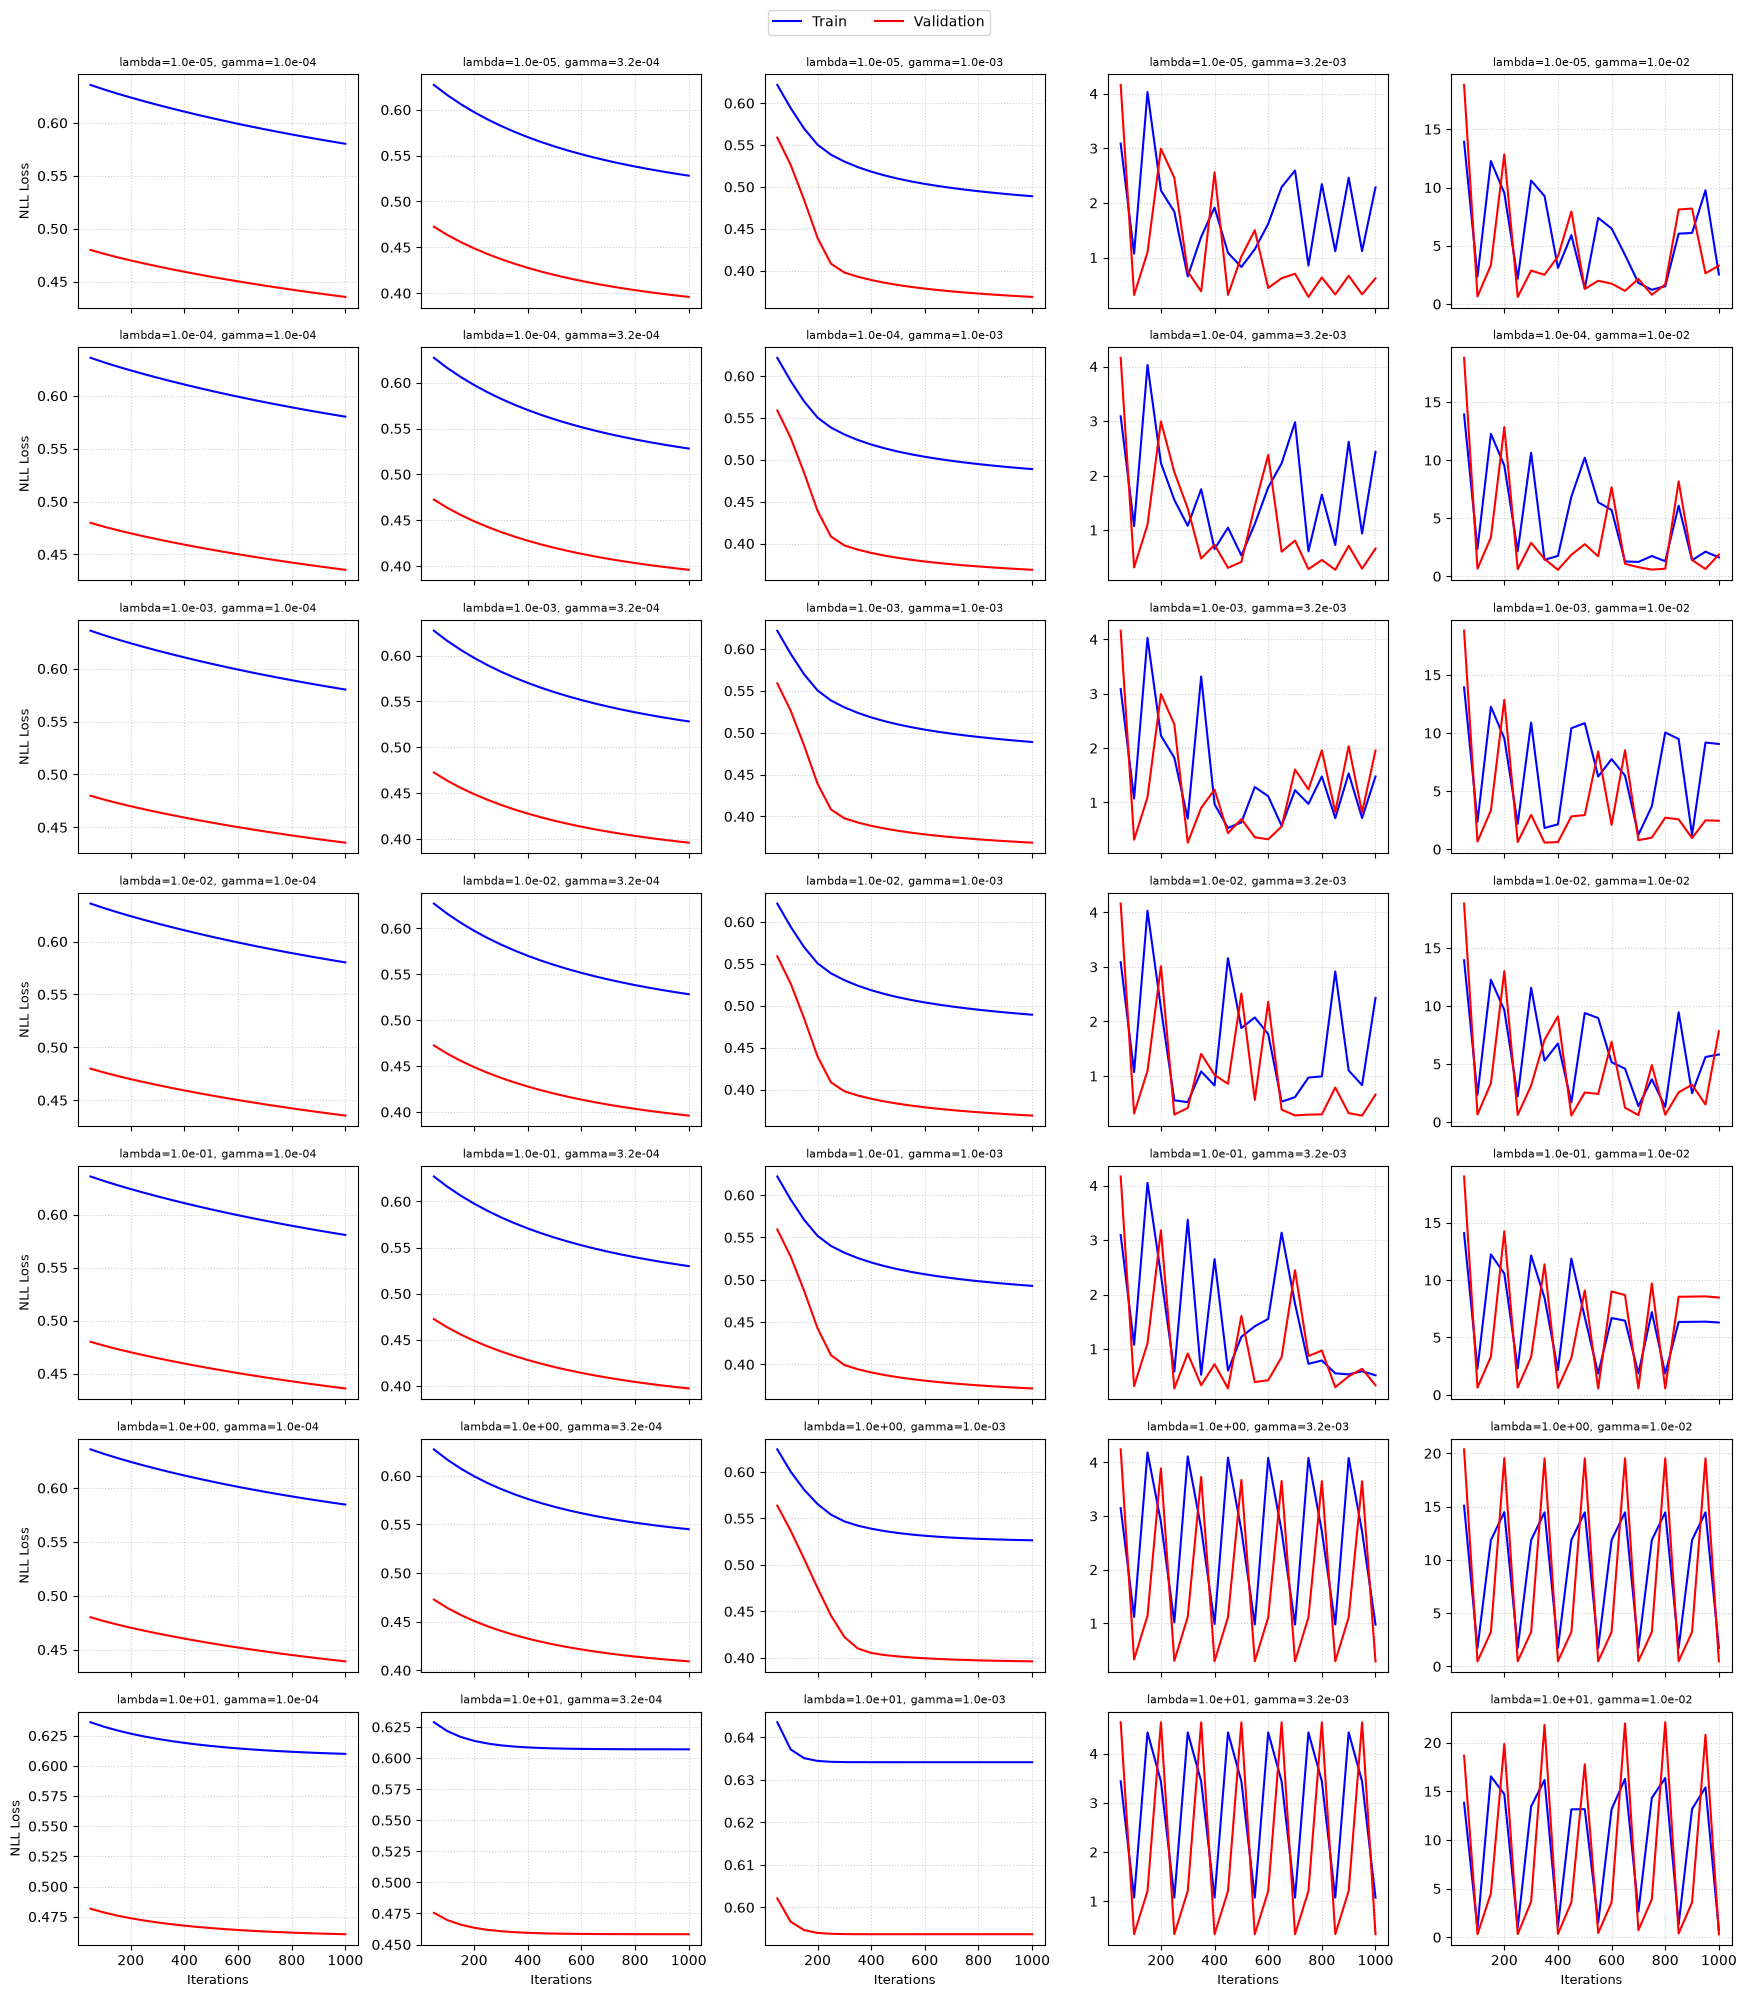

In [ ]:
iterations = np.arange(checkpoint, max_iters + 1, checkpoint)

# Create a grid of subplots (rows: lambda, cols: gamma)
fig, axes = plt.subplots(
    n_lambdas, n_gammas, figsize=(n_gammas * 3.5, n_lambdas * 2.8), sharex=True, sharey=False
)

for i, lambda_ in enumerate(lambda_values):
    for j, gamma in enumerate(gamma_values):
        ax = axes[i, j]

        # Plot train and val loss curves over iterations
        ax.plot(iterations, train_losses_grid_search[i, j, :], label="Train", color="blue", linewidth=1.5)
        ax.plot(iterations, val_losses_grid_search[i, j, :], label="Validation", color="red", linewidth=1.5)
        # Annotate each subplot with hyperparameter values
        ax.set_title(f"lambda={lambda_:.1e}, gamma={gamma:.1e}", fontsize=8)
        ax.grid(True, linestyle=":", alpha=0.6)

# Label outer axes to avoid clutter
for ax in axes[-1, :]:
    ax.set_xlabel("Iterations", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("NLL Loss", fontsize=9)

# Add a single shared legend for the whole grid
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02), fontsize=10)

plt.tight_layout()
plt.show()

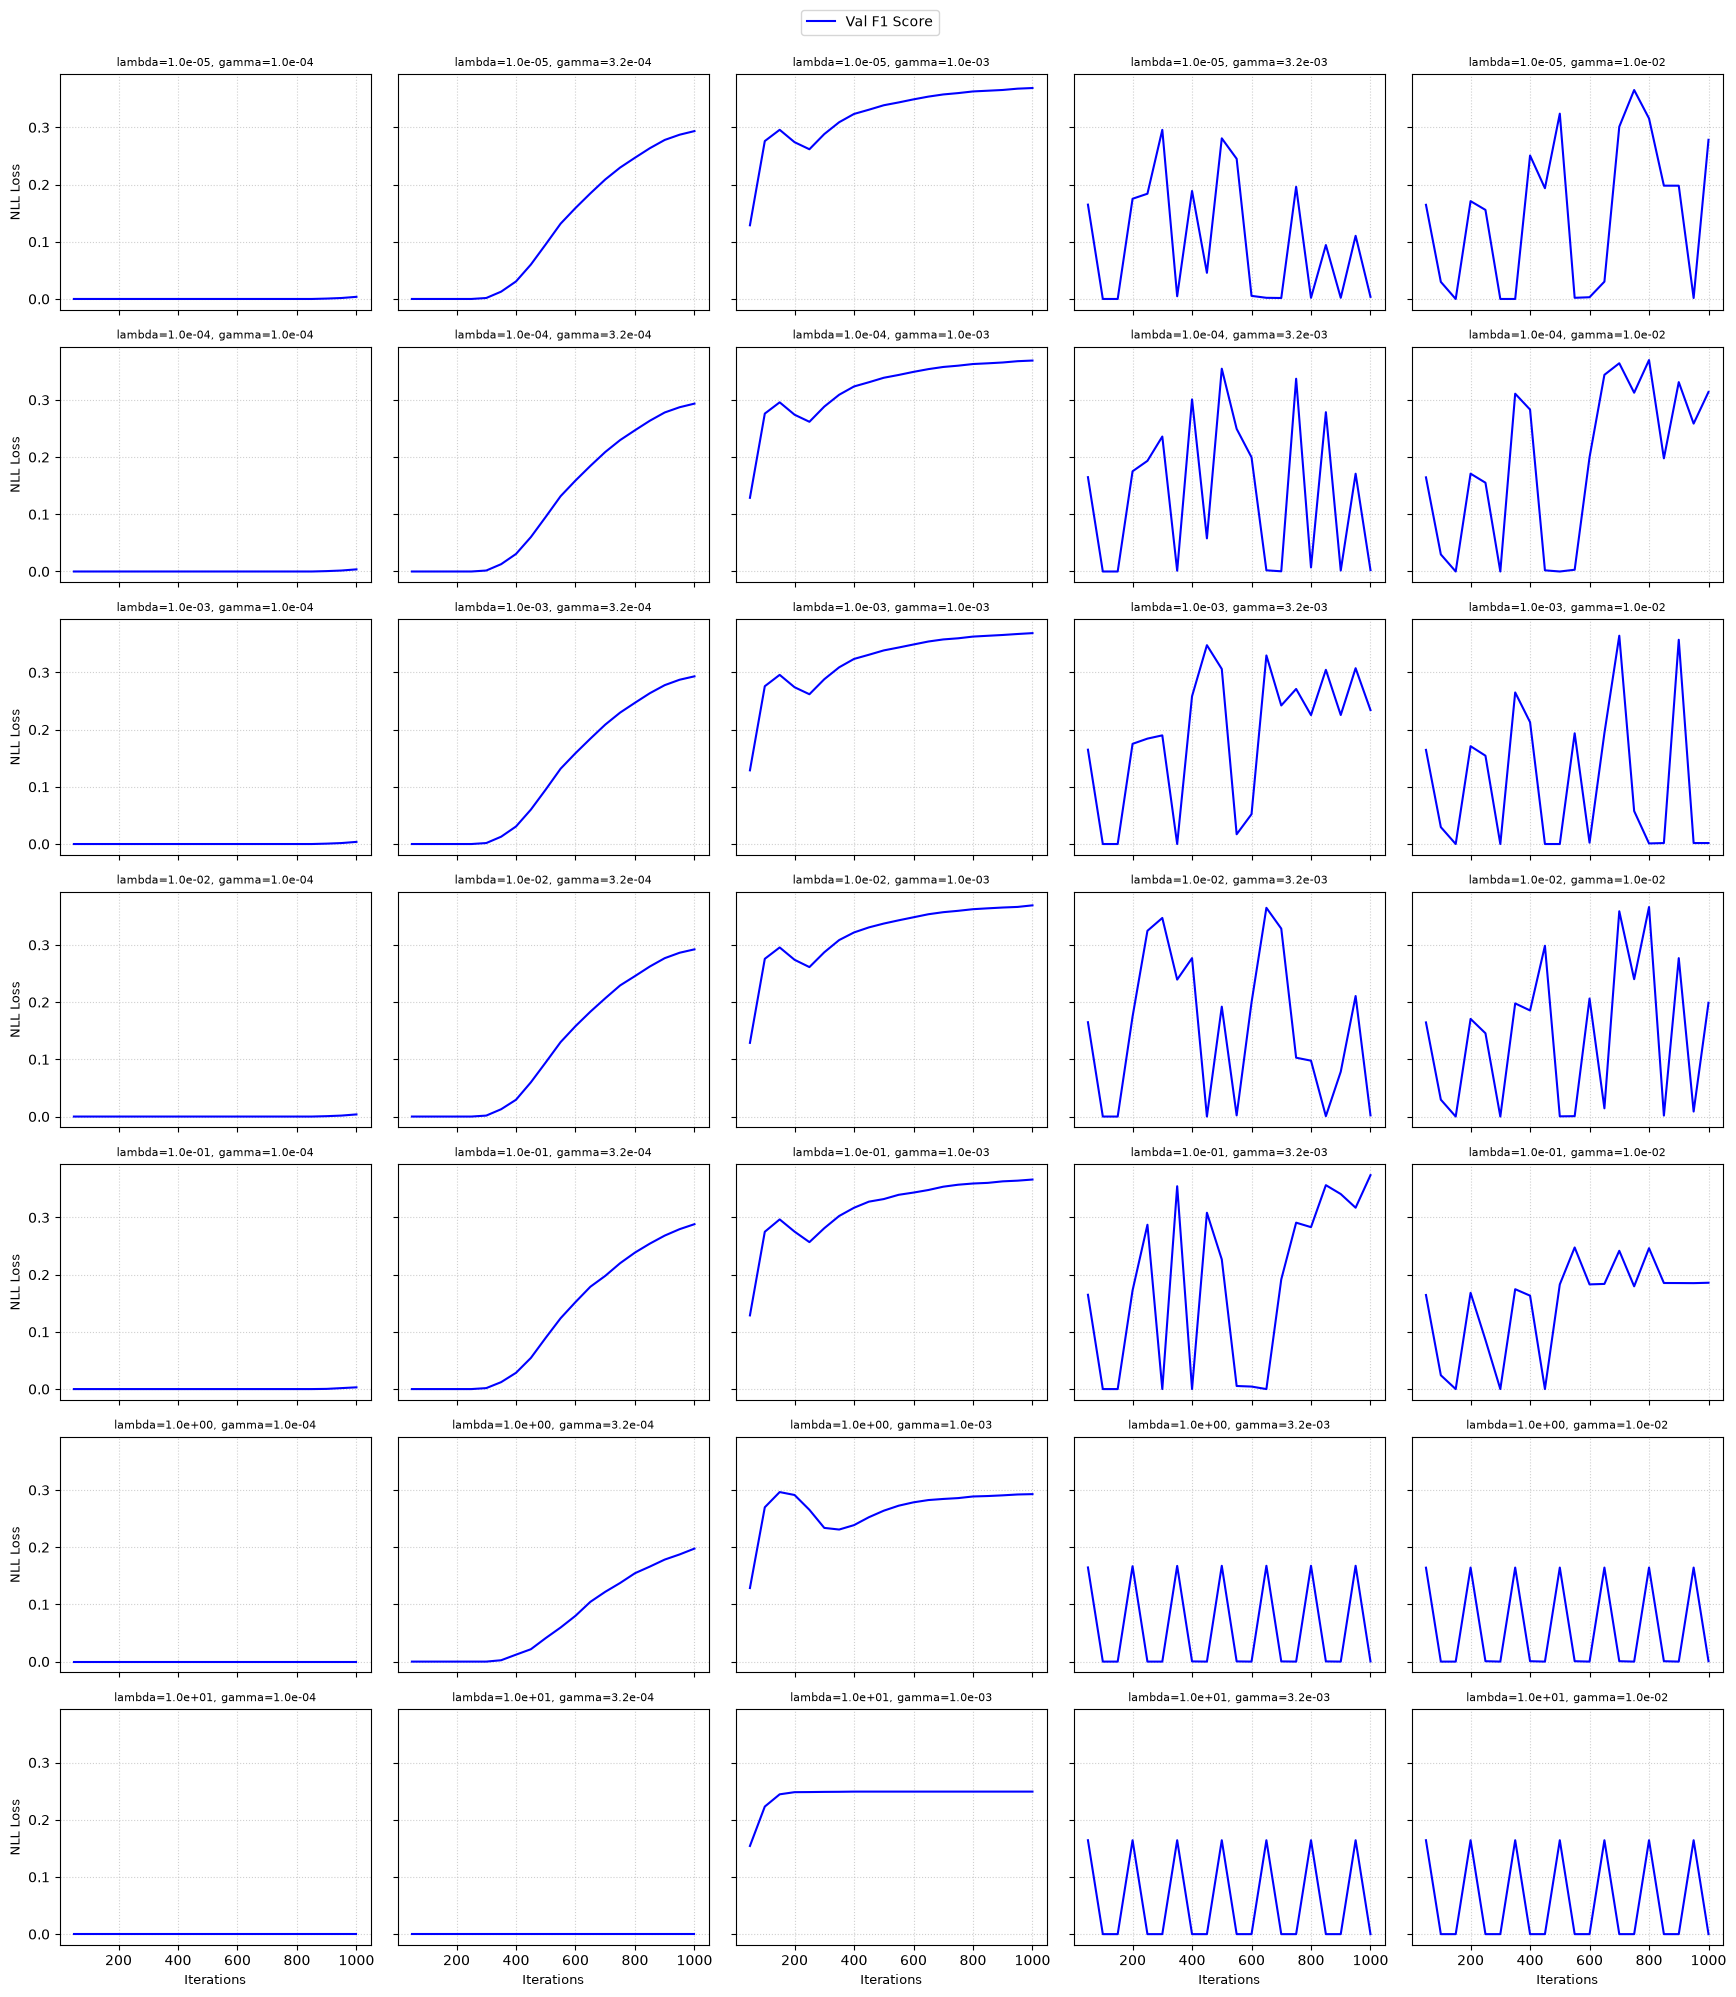

In [ ]:
iterations = np.arange(checkpoint, max_iters + 1, checkpoint)

# Create a grid of subplots (rows: lambda, cols: gamma)
fig, axes = plt.subplots(
    n_lambdas, n_gammas, figsize=(n_gammas * 3.5, n_lambdas * 2.8), sharex=True, sharey=True
)

for i, lambda_ in enumerate(lambda_values):
    for j, gamma in enumerate(gamma_values):
        ax = axes[i, j]

        # Plot train and val loss curves over iterations
        ax.plot(iterations, f1_scores_grid_search[i, j, :], label="Val F1 Score", color="blue", linewidth=1.5)
        # Annotate each subplot with hyperparameter values
        ax.set_title(f"lambda={lambda_:.1e}, gamma={gamma:.1e}", fontsize=8)
        ax.grid(True, linestyle=":", alpha=0.6)

# Label outer axes to avoid clutter
for ax in axes[-1, :]:
    ax.set_xlabel("Iterations", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("NLL Loss", fontsize=9)

# Add a single shared legend for the whole grid
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02), fontsize=10)

plt.tight_layout()
plt.show()

#### Model Training with Logistic Regression and Optimal Hyperparameters

We then train the model with the optimal hyperparameters lambda=0.001 and gamma=0.001 over 100000 steps.

We train the model incrementally and evaluate it every 50 iterations. At each
checkpoint, we store:

- the training loss,
- the validation loss,
- the model weights, and
- the validation F1-score.

The final model is selected as the checkpoint with the highest validation
F1-score. This prevents us from automatically choosing the weights from the
last iteration if the model begins to overfit before training finishes.

In [124]:
lambda_ = 1e-3
gamma = 1e-3

checkpoint = 50
max_iters = 100_000
num_checkpoints = max_iters // checkpoint

train_losses = np.zeros(num_checkpoints)
val_losses = np.zeros(num_checkpoints)
D = tx_train.shape[1]
models = np.zeros((num_checkpoints, D))
f1_scores = np.zeros(num_checkpoints)

w = np.zeros((tx_train.shape[1]))

for ckp_idx, iteration in enumerate(range(checkpoint, max_iters + 1, checkpoint)):
    w, train_loss = reg_logistic_regression(
        y_train_logistic,
        tx_train,
        lambda_,
        w,
        checkpoint,
        gamma,
    )

    train_losses[ckp_idx] = train_loss
    val_losses[ckp_idx] = negative_log_likelihood(y_val_logistic, tx_val, w)
    models[ckp_idx] = w

    predict = np.where(sigmoid(tx_val @ w) >= 0.5, 1, 0)
    f1 = f1_score(y_val_logistic, predict, pos_label=1)
    f1_scores[ckp_idx] = f1
    print(f"Checkpoint {ckp_idx} got f1 score of {f1}")

Checkpoint 0 got f1 score of 0.1288163948138854
Checkpoint 1 got f1 score of 0.27587511825922423
Checkpoint 2 got f1 score of 0.2957333821644388
Checkpoint 3 got f1 score of 0.27409390444810544
Checkpoint 4 got f1 score of 0.2618330464716007
Checkpoint 5 got f1 score of 0.28810187027457224
Checkpoint 6 got f1 score of 0.3089342403628118
Checkpoint 7 got f1 score of 0.3235593220338983
Checkpoint 8 got f1 score of 0.3308693556162623
Checkpoint 9 got f1 score of 0.3384710234278669
Checkpoint 10 got f1 score of 0.343533616260889
Checkpoint 11 got f1 score of 0.3488220369699166
Checkpoint 12 got f1 score of 0.3540275607330587
Checkpoint 13 got f1 score of 0.3576601671309192
Checkpoint 14 got f1 score of 0.35964131699637214
Checkpoint 15 got f1 score of 0.36262919678443556
Checkpoint 16 got f1 score of 0.3640611441158801
Checkpoint 17 got f1 score of 0.3654480665170912
Checkpoint 18 got f1 score of 0.36716300940438873
Checkpoint 19 got f1 score of 0.368673139158576
Checkpoint 20 got f1 score

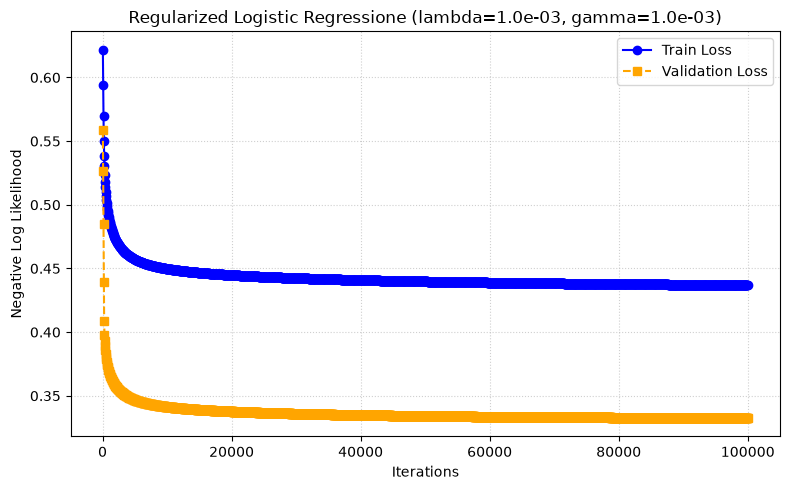

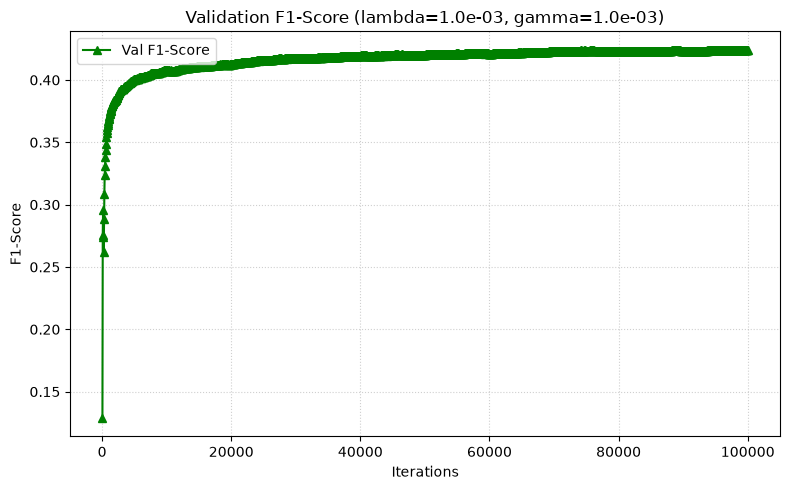

In [125]:
iterations = list(range(checkpoint, max_iters + 1, checkpoint))

# ---------------------------------------------------------
# Figure 1: Train Loss vs. Validation Loss Over Time
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(iterations, train_losses, label="Train Loss", marker="o", color="blue")
plt.plot(
    iterations,
    val_losses,
    label="Validation Loss",
    marker="s",
    color="orange",
    linestyle="--",
)

plt.title(
    f"Regularized Logistic Regressione (lambda={lambda_:.1e}, gamma={gamma:.1e})"
)
plt.xlabel("Iterations")
plt.ylabel("Negative Log Likelihood")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Figure 2: Validation F1-Score Over Time
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(iterations, f1_scores, label="Val F1-Score", marker="^", color="green")

plt.title(f"Validation F1-Score (lambda={lambda_:.1e}, gamma={gamma:.1e})")
plt.xlabel("Iterations")
plt.ylabel("F1-Score")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
best_ckp_idx = np.argmax(f1_scores)
print(f"Best checkpoint: {best_ckp_idx}")
print(f"Best validation F1-score: {f1_scores[best_ckp_idx]}")

# Save the best model weights
best_model = models[best_ckp_idx]
np.save(BEST_MODEL_FILE_PATH, best_model)
print(f"Saved best model weights to \'{BEST_MODEL_FILE_PATH}\'")

Best checkpoint: 1976
Best validation F1-score: 0.42423885519109594
Saved best model weights to 'best_model_weights.npy'


### Support Vector Machines

As a comparison, we also trained a linear SVM using stochastic gradient descent.
However, its validation F1-score was constantly 0 for the chosen hyperparameters. We therefore use logistic regression as the final model.

Final training accuracy = 67.45 %
Training time: 29.3 seconds 


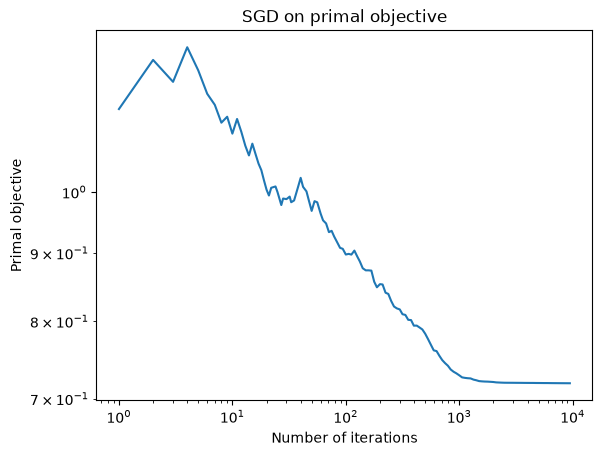

In [148]:
losses, w = sgd_for_svm_demo(y_train, tx_train, 10_000, gamma=0.0001, lambda_=10)

In [130]:
predict = tx_val @ w
predict[predict >= 0] = 1
predict[predict < 0] = -1
print("Final F1 score:", f1_score(y_val, predict, pos_label=1))

Final F1 score: 0.0


## Prediction

We apply the selected model weights to the preprocessed test data. The test
features have gone through exactly the same cleaning, imputation, feature
selection, standardization, and bias-term steps as the training data.

The model first produces a probability for the positive class using the sigmoid
function. We classify samples with probability at least `0.5` as positive (`1`);
all other samples are classified as negative (`-1`).

Finally, we write the test IDs and predictions to `test.csv` in the required
submission format. The test set is used only for generating predictions and is
not used for model selection.

In [139]:
best_model = np.load(BEST_MODEL_FILE_PATH)
print(f"Loaded best model weights from \'{BEST_MODEL_FILE_PATH}\'")

Loaded best model weights from 'best_model_weights.npy'


In [ ]:
predict_submission = np.where(sigmoid(tx_test @ best_model) >= 0.5, 1, -1)
create_csv_submission(test_ids, y_pred=predict_submission, name="test.csv")